# SciCite: Citation Intent Classification
## End-to-End Comparative Benchmark & Ablation Study

**Course:** Mesterséges intelligencia alkalmazási területei  
**Dataset:** `allenai/scicite` (Official splits from NAACL 2019 / Hugging Face)  
**Target Classes:** `method`, `background`, `result`  
**Objective:** Classify scientific citation intent using classical TF-IDF baselines and fine-tuned Transformer models (DistilBERT, ModernBERT, SciBERT), quantifying the effect of section header conditioning (`text-only` vs. `section-aware`).


In [1]:
# Environment setup and dataset loading
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

from src.data import get_data_splits, CLASS_NAMES, ID2LABEL
from src.utils import set_seed, compute_classification_metrics
from src.models import train_baseline

set_seed(42)
PROJECT_ROOT = Path(".").resolve()

train_df, val_df, test_df = get_data_splits(PROJECT_ROOT)
print("SciCite official benchmark partitions loaded successfully:")
print(f"  - Train split:       {len(train_df):>5} samples")
print(f"  - Validation split:  {len(val_df):>5} samples")
print(f"  - Test split:        {len(test_df):>5} samples")


C:\Repos\scicite-citation-intent\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SciCite official benchmark partitions loaded successfully:
  - Train split:        8194 samples
  - Validation split:    916 samples
  - Test split:         1859 samples


---
## 1. Exploratory Data Analysis & Split Integrity

### Methodological Rationale for Official Splits
In citation classification, random row-level splitting causes severe **document-level group leakage**: multiple citation sentences extracted from the same paper (`citingPaperId`) share identical authorship styles, terminology, and research topics. A naive random split leaks paper-specific cues into the test partition, inflating accuracy. 

The official splits by Cohan et al. (2019) enforce publication-level partitioning, ensuring test instances evaluate true out-of-domain generalization.


Class distribution across benchmark splits (%):


Split,Train,Val,Test
Class,,,
Background,59.1,58.7,53.6
Method,27.7,27.8,32.5
Result,13.3,13.4,13.9


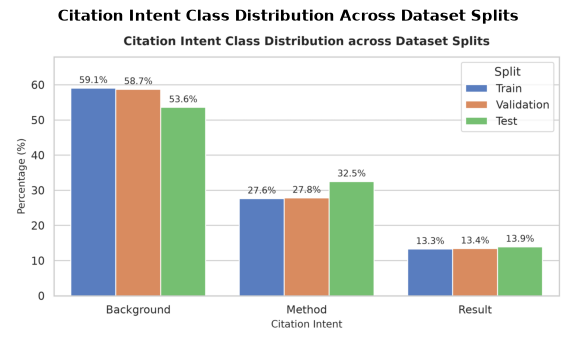

In [2]:
# 1. Label distribution across splits
class_summary = []
for split_name, df in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    for name in CLASS_NAMES:
        cnt = (df['label_name'] == name).sum()
        pct = (cnt / len(df)) * 100
        class_summary.append({"Split": split_name, "Class": name.capitalize(), "Count": cnt, "Share (%)": round(pct, 1)})

class_df = pd.DataFrame(class_summary)
pivot_df = class_df.pivot(index="Class", columns="Split", values="Share (%)")[["Train", "Val", "Test"]]
print("Class distribution across benchmark splits (%):")
display(pivot_df)

# Display class distribution figure
img_path = PROJECT_ROOT / "outputs" / "figures" / "class_distribution.png"
if img_path.is_file():
    plt.figure(figsize=(8, 4))
    plt.imshow(mpimg.imread(str(img_path)))
    plt.axis("off")
    plt.title("Citation Intent Class Distribution Across Dataset Splits", fontsize=11, fontweight="bold")
    plt.show()


---
## 2. Preprocessing & Input Representations (Ablation Study)

The raw section title field (`sectionName`) is noisy: it contains arbitrary numbering schemes (`1. Introduction`, `IV. Methods`), structural variations, and missing entries.

We normalize section headers into 7 canonical categories:
`introduction`, `method`, `result`, `discussion`, `result_discussion`, `other`, and `missing`.

### Two Comparative Input Representations:
1. **Text-only:** The citation context sentence alone (`string`).
2. **Section-aware:** Structured prefix conditioning:  
   `"Section: {canonical_section}. Citation: {string}"`


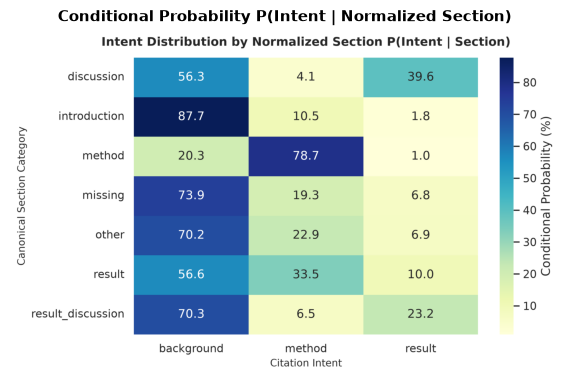

Example input representations (Train instance #1):
  True Label:         BACKGROUND
  Raw sectionName:    'Introduction' -> Normalized: 'introduction'
  [Text-only]:        However, how frataxin interacts with the Fe-S cluster biosynthesis components remains unclear as dir...
  [Section-aware]:    Section: introduction. Citation: However, how frataxin interacts with the Fe-S cluster biosynthesis components remains u...


In [3]:
# Section-intent conditional distribution heatmap: P(Intent | Section)
sec_img_path = PROJECT_ROOT / "outputs" / "figures" / "canonical_section_contingency.png"
if sec_img_path.is_file():
    plt.figure(figsize=(8, 4.5))
    plt.imshow(mpimg.imread(str(sec_img_path)))
    plt.axis("off")
    plt.title("Conditional Probability P(Intent | Normalized Section)", fontsize=11, fontweight="bold")
    plt.show()

# Sample representation comparison
sample = train_df.iloc[0]
print("Example input representations (Train instance #1):")
print(f"  True Label:         {sample['label_name'].upper()}")
print(f"  Raw sectionName:    '{sample['sectionName']}' -> Normalized: '{sample['section_clean']}'")
print(f"  [Text-only]:        {sample['text_only'][:100]}...")
print(f"  [Section-aware]:    {sample['text_section_aware'][:120]}...")


---
## 3. Baseline Model: TF-IDF + Logistic Regression

The classical baseline uses TF-IDF n-gram vectorization (1-2 grams, max 10,000 features, sublinear TF) paired with a Logistic Regression classifier. Regularization strength ($C$) and class weighting are tuned on the validation split.


In [4]:
# Fit and evaluate baseline models on official test set
print("Fitting TF-IDF + Logistic Regression baselines...")
_, base_preds_text, base_m_text = train_baseline(train_df, val_df, test_df, text_column="text_only")
_, base_preds_sec, base_m_sec = train_baseline(train_df, val_df, test_df, text_column="text_section_aware")

baseline_summary = pd.DataFrame([
    {
        "Input Mode": "Text-only",
        "Accuracy": base_m_text["accuracy"],
        "Macro F1": base_m_text["macro_f1"],
        "Method F1": base_m_text["per_class"]["method"]["f1"],
        "Background F1": base_m_text["per_class"]["background"]["f1"],
        "Result F1": base_m_text["per_class"]["result"]["f1"],
    },
    {
        "Input Mode": "Section-aware",
        "Accuracy": base_m_sec["accuracy"],
        "Macro F1": base_m_sec["macro_f1"],
        "Method F1": base_m_sec["per_class"]["method"]["f1"],
        "Background F1": base_m_sec["per_class"]["background"]["f1"],
        "Result F1": base_m_sec["per_class"]["result"]["f1"],
    },
])

print("\n=== Baseline Performance Summary (Official Test Split) ===")
display(baseline_summary)
macro_delta = (base_m_sec['macro_f1'] - base_m_text['macro_f1']) * 100
print(f"Section conditioning ablation effect on baseline: +{macro_delta:.2f}% Macro-F1 points")


Fitting TF-IDF + Logistic Regression baselines...



=== Baseline Performance Summary (Official Test Split) ===


,Input Mode,Accuracy,Macro F1,Method F1,Background F1,Result F1
0,Text-only,0.8354,0.8157,0.8106,0.8643,0.7723
1,Section-aware,0.8628,0.8405,0.8672,0.8844,0.7698


Section conditioning ablation effect on baseline: +2.48% Macro-F1 points


---
## 4. Transformer Fine-Tuning: DistilBERT, ModernBERT, and SciBERT

We evaluate three pretrained architectures representing different parameter scales and pre-training domains:
1. **DistilBERT** (`distilbert-base-uncased`, 66M parameters): Lightweight general-domain distilled baseline.
2. **ModernBERT** (`answerdotai/ModernBERT-base`, 149M parameters): Modern architecture with Rotary Position Embeddings (RoPE), GeLU activations, and efficient attention.
3. **SciBERT** (`allenai/scibert_scivocab_uncased`, 110M parameters): Domain-adapted model pre-trained on 1.14M scientific publications with a specialized scientific vocabulary (`scivocab`).

### Training Dynamics & Overfitting Analysis (10-Epoch Trajectory)
All models were monitored across 10 epochs to observe the onset of representation overfitting.


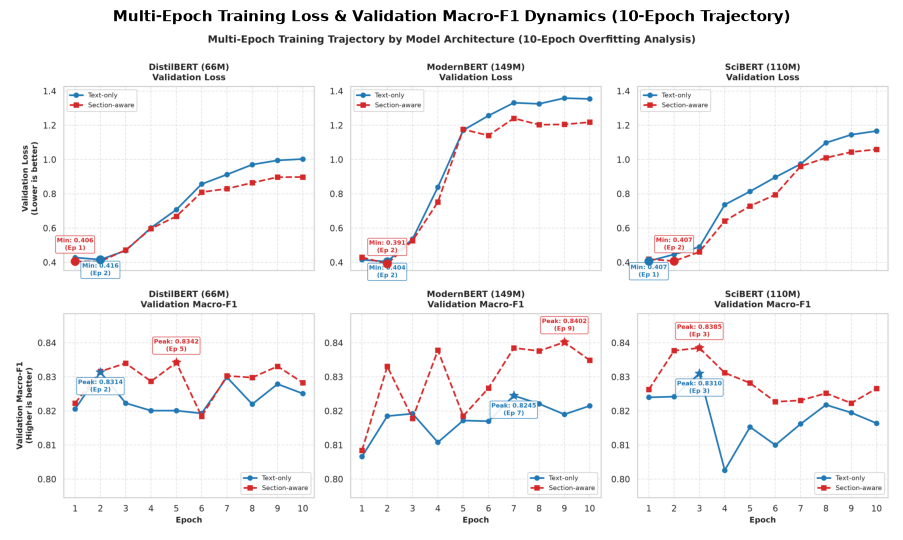

Key training dynamics observations:
  1. Validation loss reaches its global minimum at epoch 2-3 (~0.40) across all architectures.
  2. Beyond epoch 4, validation loss diverges (>1.0) while validation Macro-F1 plateaus.
  3. Checkpoint selection via 'load_best_model_at_end=True' protects test inference against overfitting.


In [5]:
# Display multi-epoch learning curves
curves_path = PROJECT_ROOT / "outputs" / "figures" / "transformer_training_curves.png"
if curves_path.is_file():
    plt.figure(figsize=(12, 6.5))
    plt.imshow(mpimg.imread(str(curves_path)))
    plt.axis("off")
    plt.title("Multi-Epoch Training Loss & Validation Macro-F1 Dynamics (10-Epoch Trajectory)", fontsize=11, fontweight="bold")
    plt.show()

print("Key training dynamics observations:")
print("  1. Validation loss reaches its global minimum at epoch 2-3 (~0.40) across all architectures.")
print("  2. Beyond epoch 4, validation loss diverges (>1.0) while validation Macro-F1 plateaus.")
print("  3. Checkpoint selection via 'load_best_model_at_end=True' protects test inference against overfitting.")


---
## 5. Comparative Evaluation & Error Analysis

The master benchmark table compares the classical baselines against all fine-tuned Transformer configurations on the official unseen test set (N=1,859).


In [6]:
# Load master benchmark leaderboard
leaderboard_path = PROJECT_ROOT / "outputs" / "reports" / "all_models_comparative_summary.csv"
leaderboard = pd.read_csv(leaderboard_path)
display_cols = ["Model", "Representation", "Accuracy", "Macro F1", "Method F1", "Background F1", "Result F1"]
display_df = leaderboard[display_cols].sort_values("Macro F1", ascending=False).reset_index(drop=True)

print("=== Master Comparative Leaderboard (Official Test Split, N=1,859) ===")
display(display_df)


=== Master Comparative Leaderboard (Official Test Split, N=1,859) ===


,Model,Representation,Accuracy,Macro F1,Method F1,Background F1,Result F1
0,ModernBERT,Section-aware,0.8725,0.8550,0.8925,0.8868,0.7858
1,SciBERT,Text-only,0.8618,0.8503,0.8559,0.8780,0.8171
2,DistilBERT,Section-aware,0.8564,0.8433,0.8586,0.8727,0.7987
3,Baseline (TF-IDF + LR),Section-aware,0.8628,0.8405,0.8672,0.8844,0.7698
4,ModernBERT,Text-only,0.8564,0.8404,0.8540,0.8764,0.7907
5,DistilBERT,Text-only,0.8548,0.8397,0.8487,0.8770,0.7933
6,SciBERT,Section-aware,0.8531,0.8392,0.8615,0.8691,0.7870
7,Baseline (TF-IDF + LR),Text-only,0.8354,0.8157,0.8106,0.8643,0.7723


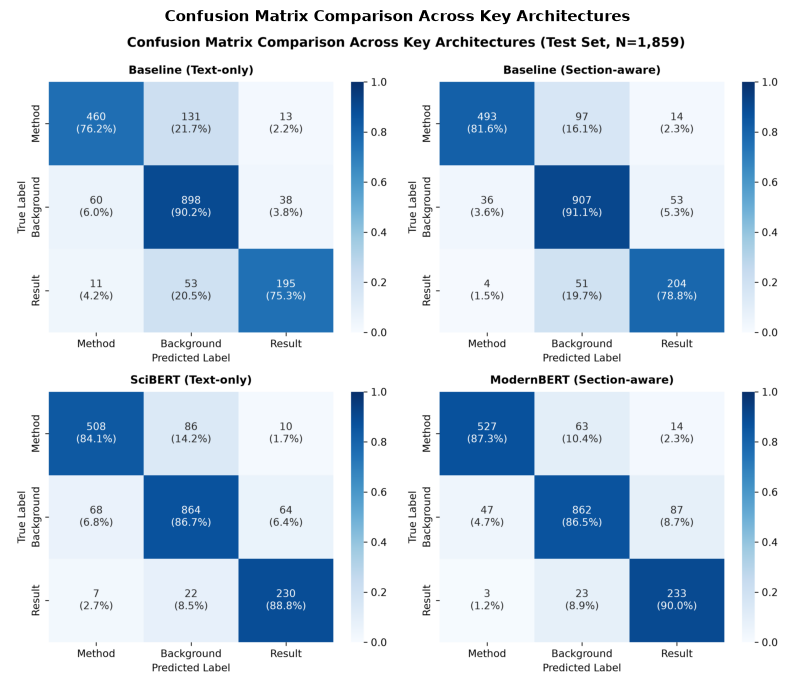

In [7]:
# Composite Confusion Matrix comparison
cm_fig_path = PROJECT_ROOT / "outputs" / "figures" / "confusion_matrices_comparison.png"
if cm_fig_path.is_file():
    plt.figure(figsize=(10, 8.5))
    plt.imshow(mpimg.imread(str(cm_fig_path)))
    plt.axis("off")
    plt.title("Confusion Matrix Comparison Across Key Architectures", fontsize=11, fontweight="bold")
    plt.show()


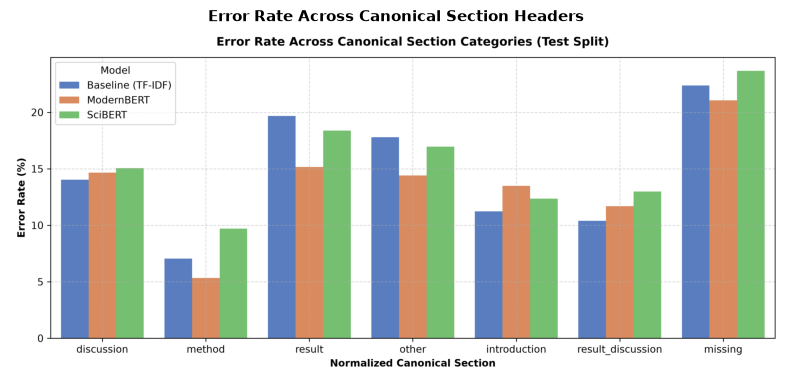


=== Representative Qualitative Case Studies ===


,Error Category,True Label,Section Header,Baseline Pred,ModernBERT Pred,SciBERT Pred,Citation Context
0,1. Context-Rescued (Method),method,result,background,method,method,"In order to activate reporter gene expression,..."
1,1. Context-Rescued (Method),method,method,background,method,method,"In diabetes mellitus, the choice of drugs or d..."
2,2. Result vs. Background Boundary,result,discussion,background,background,background,…the second most stably expressed gene identif...
3,2. Result vs. Background Boundary,result,discussion,background,background,background,These and other observations have led to the p...
4,3. Missing Section Penalty,background,missing,method,method,method,"Chapel, as well as X10 [2], UPC [3] , CoArray ..."
5,3. Missing Section Penalty,method,missing,background,background,background,"Also, indirect immunofluorescence microscopy [..."


In [8]:
# Error rate breakdown by normalized section header
err_fig_path = PROJECT_ROOT / "outputs" / "figures" / "error_rate_by_section.png"
if err_fig_path.is_file():
    plt.figure(figsize=(10, 4.5))
    plt.imshow(mpimg.imread(str(err_fig_path)))
    plt.axis("off")
    plt.title("Error Rate Across Canonical Section Headers", fontsize=11, fontweight="bold")
    plt.show()

# Qualitative error case studies
cases_path = PROJECT_ROOT / "outputs" / "errors" / "qualitative_case_studies.csv"
if cases_path.is_file():
    cases_df = pd.read_csv(cases_path)
    print("\n=== Representative Qualitative Case Studies ===")
    display(cases_df[["Error Category", "True Label", "Section Header", "Baseline Pred", "ModernBERT Pred", "SciBERT Pred", "Citation Context"]])


---
## 6. Synthesis & Conclusions

1. **Competitive Baseline:** The tuned section-aware TF-IDF baseline achieves **0.8405 Macro-F1**, but falls behind on the minority `result` class (**0.7698 F1**).
2. **Modern Architecture Performance:** `ModernBERT` with section conditioning achieves the overall highest score (**87.25% Accuracy, 0.8550 Macro-F1**).
3. **Domain Vocabulary Advantage (SciBERT):** SciBERT delivers superior performance on scientific citations even without section headers (**0.8503 Macro-F1**), excelling on the challenging `result` class (**0.8171 Result F1**).
4. **Structural Context Value:** Prepending normalized section headers consistently improves classification quality across both linear and deep neural models.
